In [1]:
import pandas as pd
from pathlib import Path

# Load the CV results from CSV files

# direction to folder where the results are stored
output_dir = Path("/Users/jonathangao/Documents/Gothenburg University/Courses/MSA220 - Statistical Learning for Big Data/Project 3/resultsModelComparisons") 


# Dataset sizes
dataset_sizes = [100, 1000, 5000, 10000]

# Store everything in a dictionary
results = {}

for n in dataset_sizes:
    n_str = n

    results[n] = {
        'accuracy': pd.read_csv(output_dir / f'accuracies_n_{n_str}.csv'),
        'balanced_accuracy': pd.read_csv(output_dir / f'balanced_accuracies_n_{n_str}.csv'),
        'cross_entropy': pd.read_csv(output_dir / f'cross_entropies_n_{n_str}.csv'),
        'brier': pd.read_csv(output_dir / f'brier_scores_n_{n_str}.csv')
    }


print("successfully loaded results for dataset sizes:", results.keys())


successfully loaded results for dataset sizes: dict_keys([100, 1000, 5000, 10000])


### Show boxplots with the different metrics

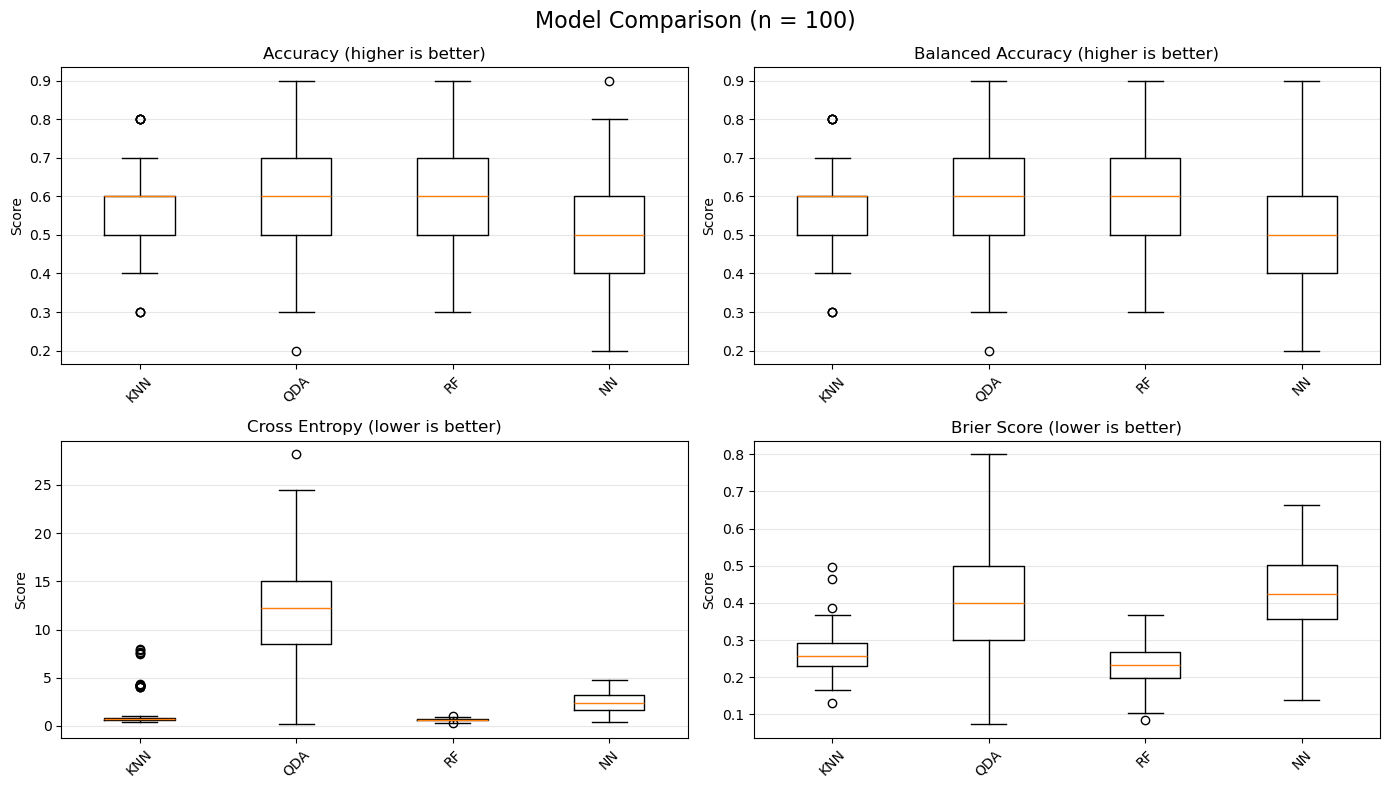

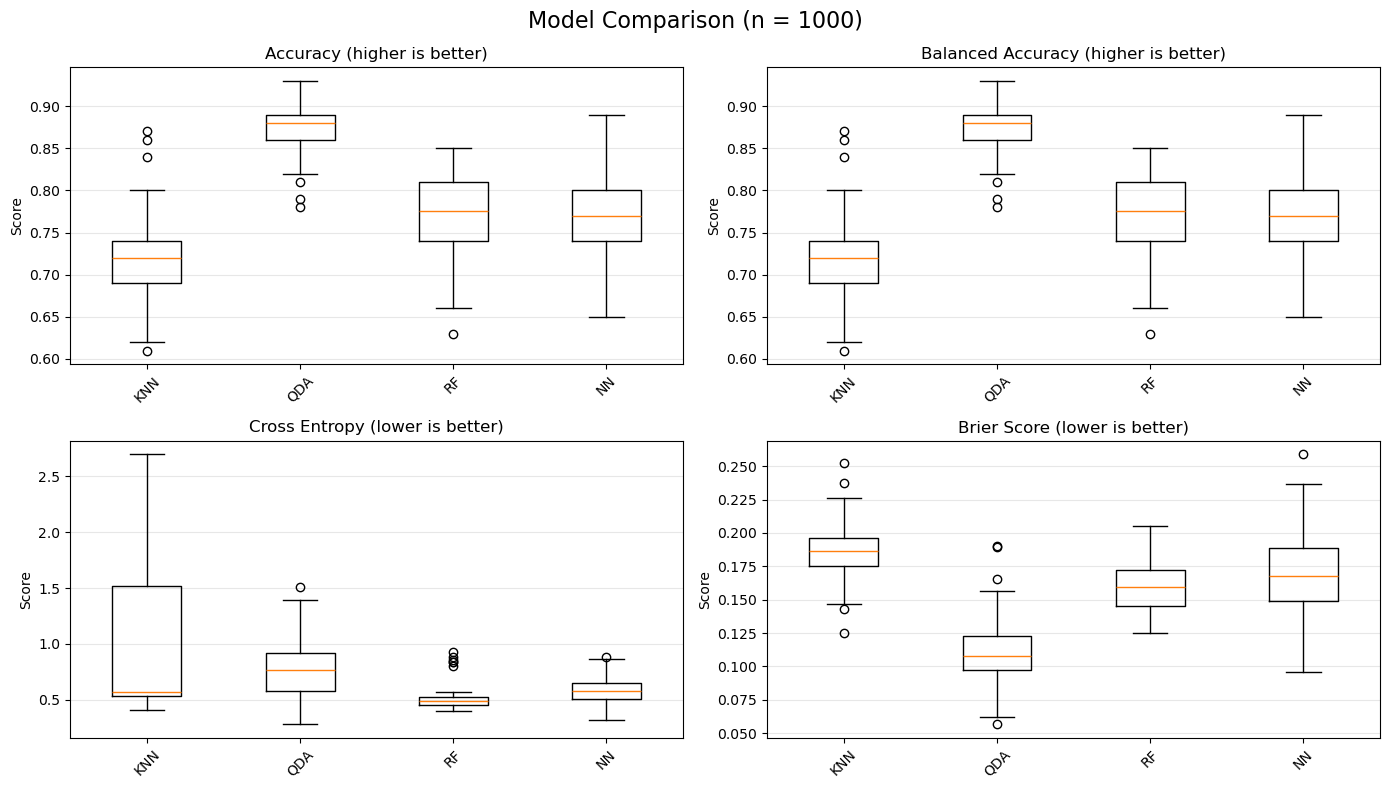

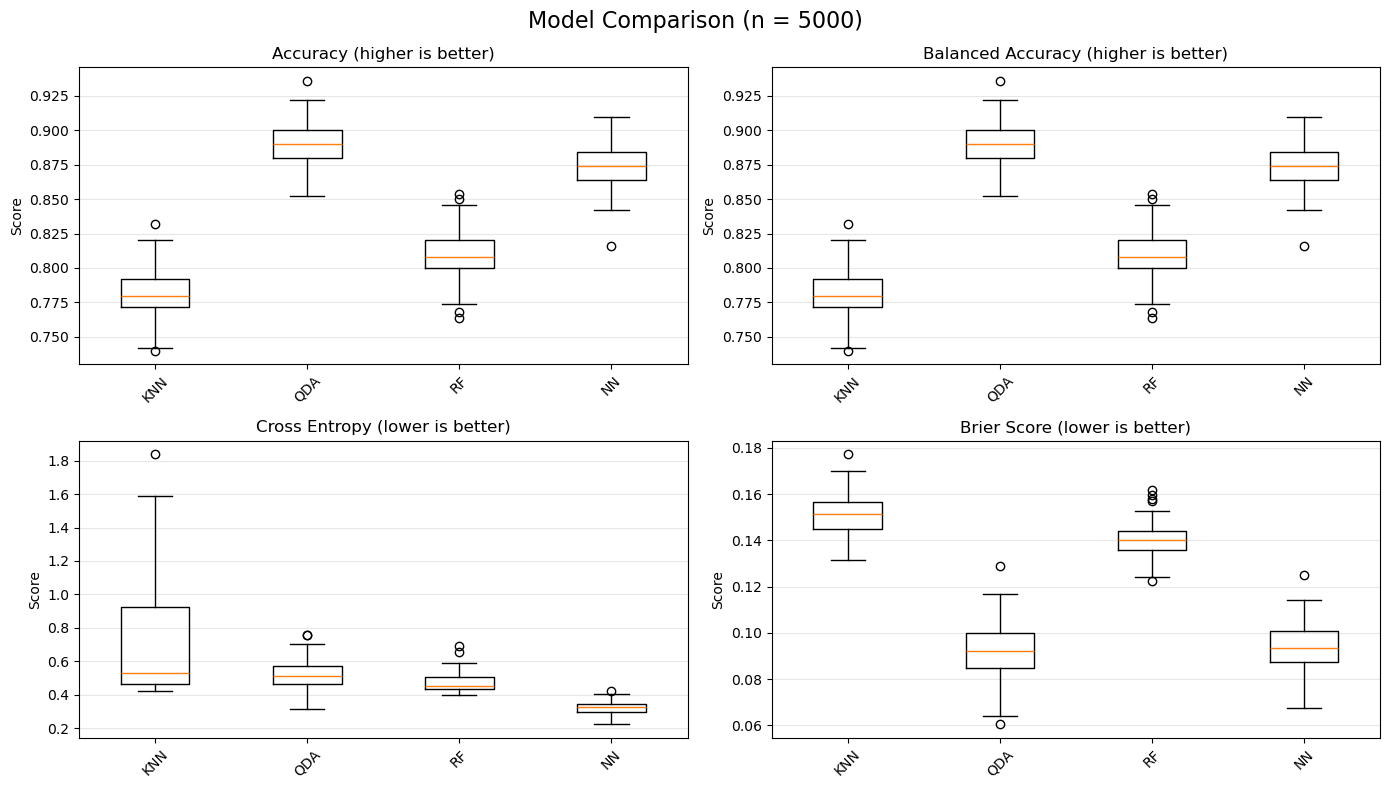

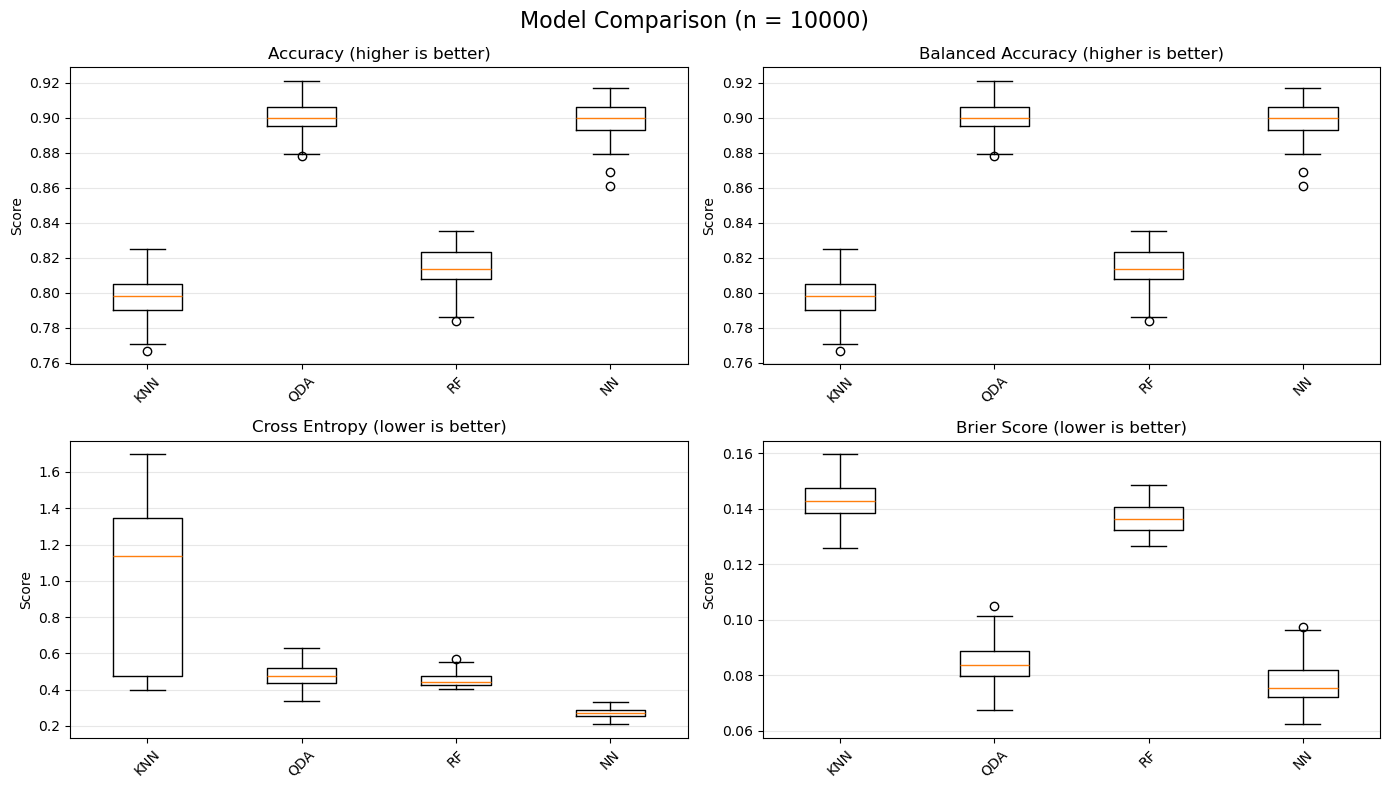

In [2]:
import matplotlib.pyplot as plt
import numpy as np


def plot_metric_boxplots(metrics_dict, n):
    """
    Plot boxplots for all metrics for one dataset size.
    """

    accuracy = metrics_dict['accuracy']
    balanced_accuracy = metrics_dict['balanced_accuracy']
    cross_entropy = metrics_dict['cross_entropy']
    brier = metrics_dict['brier']

    model_names = list(accuracy.columns)
    n_methods = len(model_names)

    fig, axes = plt.subplots(2, 2, figsize=(14, 8))
    axes = axes.flatten()

    metrics = [
        (accuracy, 'Accuracy', True),
        (balanced_accuracy, 'Balanced Accuracy', True),
        (cross_entropy, 'Cross Entropy', False),
        (brier, 'Brier Score', False)
    ]

    for ax, (metric_df, title, higher_is_better) in zip(axes, metrics):
        arr = metric_df.values

        ax.boxplot(
            [arr[:, i] for i in range(n_methods)],
            tick_labels=model_names
        )

        direction = 'higher is better' if higher_is_better else 'lower is better'

        ax.set_title(f'{title} ({direction})')
        ax.set_ylabel('Score')
        ax.grid(axis='y', alpha=0.3)
        ax.tick_params(axis='x', rotation=45)

    fig.suptitle(f'Model Comparison (n = {n})', fontsize=16)
    plt.tight_layout()
    plt.show()

for n in dataset_sizes:
    plot_metric_boxplots(results[n], n)

## Part 1 - Analysis on balanced accuracy 

#### Friedman test

In [3]:
import numpy as np
from scipy.stats import friedmanchisquare

import numpy as np
from scipy.stats import friedmanchisquare


def run_friedman_test(scores_df, metric_name, n):
    scores_array = np.asarray(scores_df)

    print('=' * 70)
    print(f'FRIEDMAN TEST — {metric_name} — n={n}')
    print('=' * 70)

    stat, pval = friedmanchisquare(*scores_array.T)

    print(f'Test statistic: {stat:.6f}')
    print(f'P-value: {pval:.6e}')
    print(f'Number of methods: {scores_array.shape[1]}')
    print(f'Number of folds: {scores_array.shape[0]}')

    if pval < 0.05:
        print('Result: Significant differences detected.')
    else:
        print('Result: No significant differences detected.')

    print()

    return stat, pval

for n in dataset_sizes:
    run_friedman_test(
        results[n]['balanced_accuracy'],
        'Balanced Accuracy',
        n
    )
    

FRIEDMAN TEST — Balanced Accuracy — n=100
Test statistic: 16.734533
P-value: 8.013753e-04
Number of methods: 4
Number of folds: 100
Result: Significant differences detected.

FRIEDMAN TEST — Balanced Accuracy — n=1000
Test statistic: 216.857582
P-value: 9.593802e-47
Number of methods: 4
Number of folds: 100
Result: Significant differences detected.

FRIEDMAN TEST — Balanced Accuracy — n=5000
Test statistic: 267.959759
P-value: 8.528337e-58
Number of methods: 4
Number of folds: 100
Result: Significant differences detected.

FRIEDMAN TEST — Balanced Accuracy — n=10000
Test statistic: 259.853119
P-value: 4.837021e-56
Number of methods: 4
Number of folds: 100
Result: Significant differences detected.



#### pairwise Wilcoxon tests with Holm correction

In [4]:
from scipy.stats import wilcoxon
from itertools import combinations
from statsmodels.stats.multitest import multipletests


def run_pairwise_tests(scores_df, metric_name, n):
    print('\n' + '=' * 70)
    print(f'POST-HOC PAIRWISE COMPARISONS — {metric_name} — n={n}')
    print('=' * 70)

    n_methods = scores_df.shape[1]
    method_names = list(scores_df.columns)

    pvals_raw = []
    comparisons = []

    for i, j in combinations(range(n_methods), 2):
        stat, pval = wilcoxon(scores_df.iloc[:, i], scores_df.iloc[:, j])

        pvals_raw.append(pval)
        comparisons.append((method_names[i], method_names[j], stat, pval))

    reject, pvals_corrected, _, _ = multipletests(
        pvals_raw,
        method='holm'
    )

    print('\nAdjusted Results:')

    for (m1, m2, stat, raw_p), corrected_p, rej in zip(
        comparisons,
        pvals_corrected,
        reject
    ):
        sig = 'SIGNIFICANT' if rej else 'not significant'

        print(
            f'{m1} vs {m2}: '
            f'raw p={raw_p:.6f}, '
            f'corrected p={corrected_p:.6f} '
            f'-> {sig}'
        )

for n in dataset_sizes:
    run_pairwise_tests(
        results[n]['balanced_accuracy'],
        'Balanced Accuracy',
        n
    )


POST-HOC PAIRWISE COMPARISONS — Balanced Accuracy — n=100

Adjusted Results:
KNN vs QDA: raw p=0.038205, corrected p=0.091277 -> not significant
KNN vs RF: raw p=0.022819, corrected p=0.091277 -> not significant
KNN vs NN: raw p=0.022885, corrected p=0.091277 -> not significant
QDA vs RF: raw p=0.706980, corrected p=0.706980 -> not significant
QDA vs NN: raw p=0.000517, corrected p=0.002587 -> SIGNIFICANT
RF vs NN: raw p=0.000063, corrected p=0.000377 -> SIGNIFICANT

POST-HOC PAIRWISE COMPARISONS — Balanced Accuracy — n=1000

Adjusted Results:
KNN vs QDA: raw p=0.000000, corrected p=0.000000 -> SIGNIFICANT
KNN vs RF: raw p=0.000000, corrected p=0.000000 -> SIGNIFICANT
KNN vs NN: raw p=0.000000, corrected p=0.000000 -> SIGNIFICANT
QDA vs RF: raw p=0.000000, corrected p=0.000000 -> SIGNIFICANT
QDA vs NN: raw p=0.000000, corrected p=0.000000 -> SIGNIFICANT
RF vs NN: raw p=0.911507, corrected p=0.911507 -> not significant

POST-HOC PAIRWISE COMPARISONS — Balanced Accuracy — n=5000

Adjust

#### Post hoc adjustment: Conover

From Rebeckas notebook:

"Conover uses the ranks from the Friedman test and estimates the variance of the rank distribution by pooling across the methods. The p-values are approximate relying on a normal approximation which holds for roughly N>10."

In [5]:
import scikit_posthocs as sp


def run_conover_test(scores_df, metric_name, n):
    print('=' * 70)
    print(f'CONOVER-FRIEDMAN TEST — {metric_name} — n={n}')
    print('=' * 70)

    p_conover = sp.posthoc_conover_friedman(
        scores_df,
        p_adjust='holm'
    )

    print(p_conover.round(6))

    return p_conover

for n in dataset_sizes:
    run_conover_test(
        results[n]['balanced_accuracy'],
        'Balanced Accuracy',
        n
    )

CONOVER-FRIEDMAN TEST — Balanced Accuracy — n=100
         KNN       QDA        RF        NN
KNN  1.00000  0.247810  0.247810  0.247810
QDA  0.24781  1.000000  0.858493  0.001803
RF   0.24781  0.858493  1.000000  0.002886
NN   0.24781  0.001803  0.002886  1.000000
CONOVER-FRIEDMAN TEST — Balanced Accuracy — n=1000
     KNN  QDA        RF        NN
KNN  1.0  0.0  0.000000  0.000000
QDA  0.0  1.0  0.000000  0.000000
RF   0.0  0.0  1.000000  0.432556
NN   0.0  0.0  0.432556  1.000000
CONOVER-FRIEDMAN TEST — Balanced Accuracy — n=5000
     KNN  QDA   RF   NN
KNN  1.0  0.0  0.0  0.0
QDA  0.0  1.0  0.0  0.0
RF   0.0  0.0  1.0  0.0
NN   0.0  0.0  0.0  1.0
CONOVER-FRIEDMAN TEST — Balanced Accuracy — n=10000
     KNN      QDA   RF       NN
KNN  1.0  0.00000  0.0  0.00000
QDA  0.0  1.00000  0.0  0.05302
RF   0.0  0.00000  1.0  0.00000
NN   0.0  0.05302  0.0  1.00000


#### post-hoc adjustment: Nemenyi

From Rebeckas notebook: 

"Nemenyi compares the average ranks between two methods and compare to a so-called critical difference, CD. The value for CD increases with the number of methods you compare and decreases with the number of data sets (splits). Methods that are more than CD apart in their average rank are deemed to differ significantly in terms of performance. Nemenyi is more conservative than conover and its popularity has lessened due to this."

In [6]:
def run_nemenyi_test(scores_df, metric_name, n):
    print('=' * 70)
    print(f'NEMENYI TEST — {metric_name} — n={n}')
    print('=' * 70)

    p_nemenyi = sp.posthoc_nemenyi_friedman(scores_df)

    print(p_nemenyi.round(6))

    return p_nemenyi

for n in dataset_sizes:
    run_nemenyi_test(
        results[n]['balanced_accuracy'],
        'Balanced Accuracy',
        n
    )

NEMENYI TEST — Balanced Accuracy — n=100
          KNN       QDA        RF        NN
KNN  1.000000  0.310405  0.401109  0.354318
QDA  0.310405  1.000000  0.998423  0.004208
RF   0.401109  0.998423  1.000000  0.007405
NN   0.354318  0.004208  0.007405  1.000000
NEMENYI TEST — Balanced Accuracy — n=1000
          KNN  QDA        RF        NN
KNN  1.000000  0.0  0.000000  0.000001
QDA  0.000000  1.0  0.000000  0.000000
RF   0.000000  0.0  1.000000  0.976618
NN   0.000001  0.0  0.976618  1.000000
NEMENYI TEST — Balanced Accuracy — n=5000
          KNN       QDA        RF        NN
KNN  1.000000  0.000000  0.000466  0.000000
QDA  0.000000  1.000000  0.000000  0.005602
RF   0.000466  0.000000  1.000000  0.000000
NN   0.000000  0.005602  0.000000  1.000000
NEMENYI TEST — Balanced Accuracy — n=10000
          KNN      QDA        RF       NN
KNN  1.000000  0.00000  0.000145  0.00000
QDA  0.000000  1.00000  0.000000  0.89237
RF   0.000145  0.00000  1.000000  0.00000
NN   0.000000  0.89237  0.000

CRITICAL DIFFERENCE DIAGRAM — Balanced Accuracy — n=100


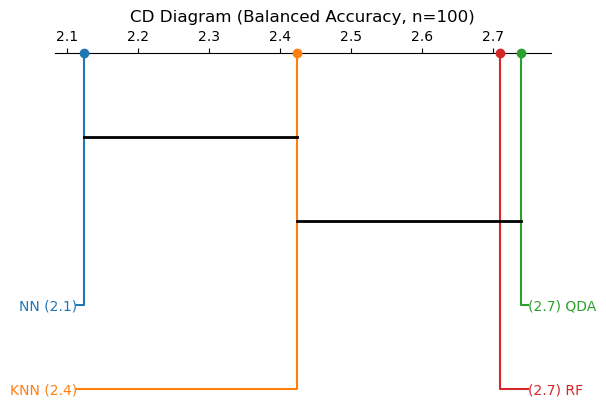

CRITICAL DIFFERENCE DIAGRAM — Balanced Accuracy — n=1000


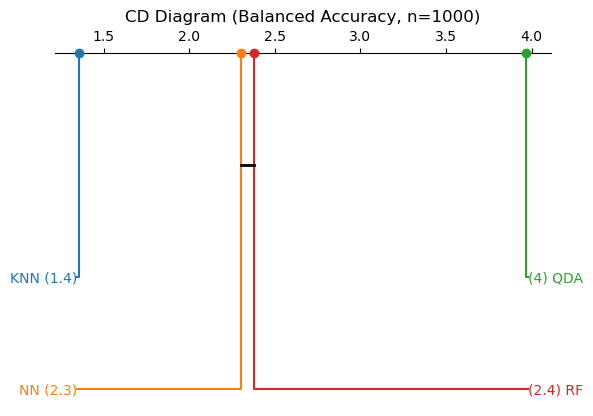

CRITICAL DIFFERENCE DIAGRAM — Balanced Accuracy — n=5000


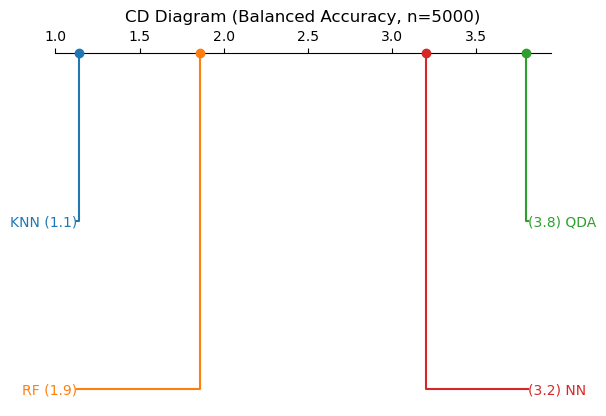

CRITICAL DIFFERENCE DIAGRAM — Balanced Accuracy — n=10000


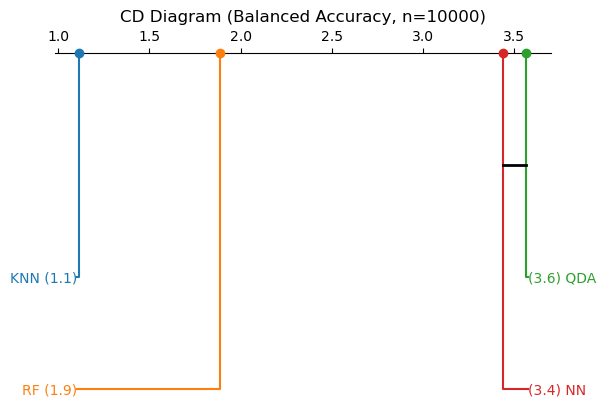

In [7]:
from scipy.stats import rankdata
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import scikit_posthocs as sp


def plot_cd_diagram(scores_df, metric_name, n):
    ranks = np.array([
        rankdata(row)
        for row in scores_df.values
    ])

    mean_ranks = ranks.mean(axis=0)

    mean_ranks_series = pd.Series(
        mean_ranks,
        index=scores_df.columns
    )

    print('=' * 70)
    print(f'CRITICAL DIFFERENCE DIAGRAM — {metric_name} — n={n}')
    print('=' * 70)

    p_nemenyi = sp.posthoc_nemenyi_friedman(scores_df) # Uses p-values from Nemenyi test for CD diagram!


    # Create symmetric p-value DataFrame for CD diagram
    p_nemenyi_for_cd = pd.DataFrame(p_nemenyi, 
                                    index=scores_df.columns, 
                                    columns=scores_df.columns)

    sp.critical_difference_diagram(
        mean_ranks_series,
        p_nemenyi_for_cd
    )

    plt.title(f'CD Diagram ({metric_name}, n={n})')
    plt.show()


# Plot CD diagrams for each dataset size for balanced accuracy
for n in dataset_sizes:
    plot_cd_diagram(
        results[n]['balanced_accuracy'],
        'Balanced Accuracy',
        n
    )


#### group models based on thresholded p-values

From Rebeckas notebook:

"The CD diagrams define the groups of methods that are indistinguishable in terms of performance. Another way to achieve this is to create a graph based on thresholded p-values and extract the connected components."


GROUPED SCORES PLOT — DATASET SIZE n = 100


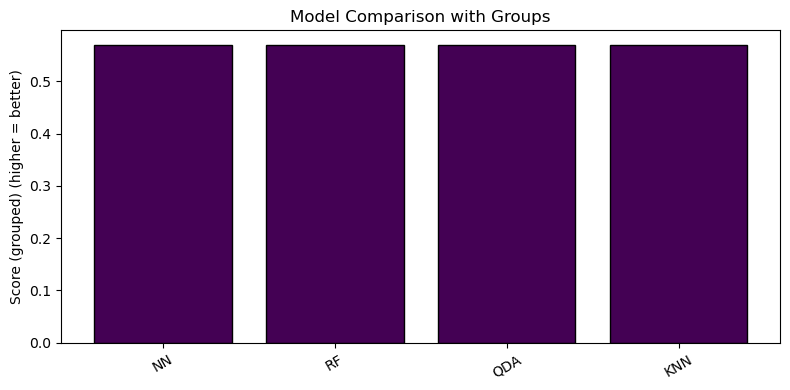


GROUPED SCORES PLOT — DATASET SIZE n = 1000


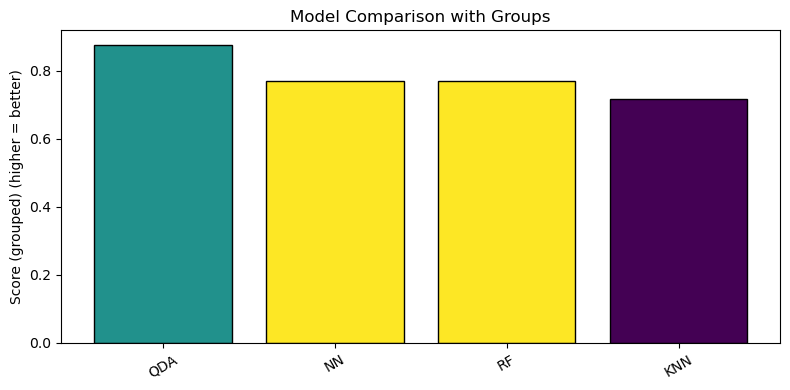


GROUPED SCORES PLOT — DATASET SIZE n = 5000


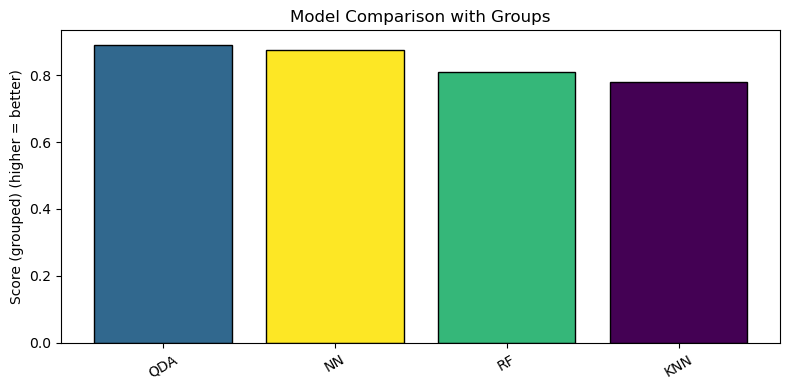


GROUPED SCORES PLOT — DATASET SIZE n = 10000


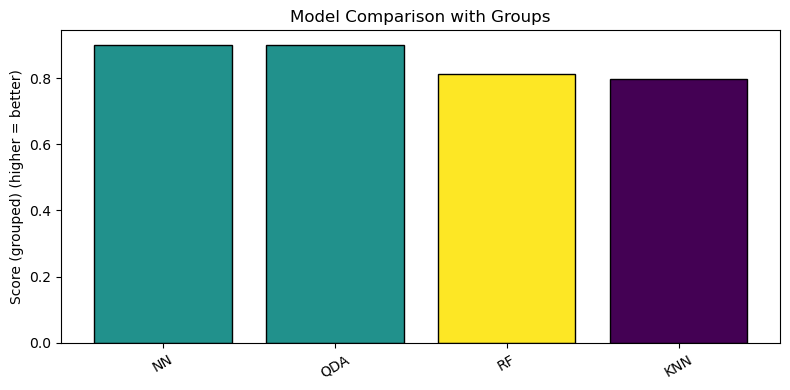

In [8]:
import networkx as nx
import matplotlib.pyplot as plt
import numpy as np


def conover_groups_graph(p_matrix, alpha=0.05):
    M = p_matrix.shape[0]

    G = nx.Graph()
    G.add_nodes_from(range(M))

    for i in range(M):
        for j in range(i+1, M):
            if p_matrix[i, j] >= alpha:
                G.add_edge(i, j)

    return list(nx.connected_components(G))

def rank_groups(groups, score, higher_is_better=True):
    score = np.asarray(score) 

    ranked = []

    for g in groups:
        g_list = list(g)
        g_score = np.mean([score[i] for i in g_list])

        ranked.append((g_list, g_score))

    ranked.sort(key=lambda x: x[1], reverse=higher_is_better)

    return ranked


def groups_to_rank_vector(groups, M):
    rank_vec = np.zeros(M)

    for rank, group in enumerate(groups, start=1):
        for i in group:
            rank_vec[i] = rank

    return rank_vec

def grouped_scores(groups, score):
    """
    Compute grouped score vector (same value within groups).

    Returns scores in ORIGINAL order.
    """
    score = np.asarray(score)
    M = len(score)

    group_scores = np.zeros(M)

    for g in groups:
        g = list(g)
        s = np.mean(score[g])
        for i in g:
            group_scores[i] = s

    return group_scores

def plot_grouped_scores(
    groups,
    score,
    names,
    higher_is_better=True,
    plot=True
):
    import numpy as np
    import matplotlib.pyplot as plt

    score = np.asarray(score)
    names = list(names)
    M = len(score)

    group_scores = np.zeros(M)

    for g in groups:
        g = list(g)
        s = np.mean(score[g])
        for i in g:
            group_scores[i] = s

    if plot is False:
        return group_scores


    group_ids = np.zeros(M)

    for gid, g in enumerate(groups):
        for i in g:
            group_ids[i] = gid

    colors = group_ids / group_ids.max() if group_ids.max() > 0 else group_ids

    order = np.argsort(group_scores)

    if higher_is_better:
        order = order[::-1]

    grouped_sorted = group_scores[order]
    names_sorted = np.array(names)[order]
    colors_sorted = colors[order]

    plt.figure(figsize=(8, 4))

    plt.bar(
        names_sorted,
        grouped_sorted,
        color=plt.cm.viridis(colors_sorted),
        edgecolor='black'
    )

    plt.xticks(rotation=30)

    ylabel = "Score (grouped)"
    ylabel += " (higher = better)" if higher_is_better else " (lower = better)"

    plt.ylabel(ylabel)
    plt.title("Model Comparison with Groups")

    plt.tight_layout()
    plt.show()

    return group_scores

for n in dataset_sizes:

    balanced_accuracy = results[n]['balanced_accuracy']

    p_conover = sp.posthoc_conover_friedman(
        balanced_accuracy,
        p_adjust='holm'
    )

    p_conover_sym = np.array(p_conover, copy=True)

    groups = conover_groups_graph(p_conover_sym, 0.05)

    print("\n" + "="*60)
    print(f"GROUPED SCORES PLOT — DATASET SIZE n = {n}")
    print("="*60)

    plot_grouped_scores(


        groups,
        balanced_accuracy.mean(axis=0),
        list(balanced_accuracy.columns),
        higher_is_better=True,
        plot=True
    )



## Part 1 - Analysis of cross-entropy

#### friedman test

In [9]:
import numpy as np
from scipy.stats import friedmanchisquare



def run_friedman_test(scores_df, metric_name, n):
    scores_array = np.asarray(scores_df)

    print('=' * 70)
    print(f'FRIEDMAN TEST — {metric_name} — n={n}')
    print('=' * 70)

    stat, pval = friedmanchisquare(*scores_array.T)

    print(f'Test statistic: {stat:.6f}')
    print(f'P-value: {pval:.6e}')
    print(f'Number of methods: {scores_array.shape[1]}')
    print(f'Number of folds: {scores_array.shape[0]}')

    if pval < 0.05:
        print('Result: Significant differences detected.')
    else:
        print('Result: No significant differences detected.')

    print()

    return stat, pval

for n in dataset_sizes:
    run_friedman_test(
        results[n]['cross_entropy'],
        'Cross Entropy',
        n
    )
    

FRIEDMAN TEST — Cross Entropy — n=100
Test statistic: 220.116000
P-value: 1.895150e-47
Number of methods: 4
Number of folds: 100
Result: Significant differences detected.

FRIEDMAN TEST — Cross Entropy — n=1000
Test statistic: 96.156000
P-value: 1.041997e-20
Number of methods: 4
Number of folds: 100
Result: Significant differences detected.

FRIEDMAN TEST — Cross Entropy — n=5000
Test statistic: 199.908000
P-value: 4.416120e-43
Number of methods: 4
Number of folds: 100
Result: Significant differences detected.

FRIEDMAN TEST — Cross Entropy — n=10000
Test statistic: 219.348000
P-value: 2.777541e-47
Number of methods: 4
Number of folds: 100
Result: Significant differences detected.



#### pairwise wilcoxon tests with Holm correction

In [10]:
from scipy.stats import wilcoxon
from itertools import combinations
from statsmodels.stats.multitest import multipletests


for n in dataset_sizes:
    run_pairwise_tests(
        results[n]['cross_entropy'],
        'Cross Entropy',
        n
    )


POST-HOC PAIRWISE COMPARISONS — Cross Entropy — n=100

Adjusted Results:
KNN vs QDA: raw p=0.000000, corrected p=0.000000 -> SIGNIFICANT
KNN vs RF: raw p=0.000016, corrected p=0.000016 -> SIGNIFICANT
KNN vs NN: raw p=0.000000, corrected p=0.000000 -> SIGNIFICANT
QDA vs RF: raw p=0.000000, corrected p=0.000000 -> SIGNIFICANT
QDA vs NN: raw p=0.000000, corrected p=0.000000 -> SIGNIFICANT
RF vs NN: raw p=0.000000, corrected p=0.000000 -> SIGNIFICANT

POST-HOC PAIRWISE COMPARISONS — Cross Entropy — n=1000

Adjusted Results:
KNN vs QDA: raw p=0.074904, corrected p=0.074904 -> not significant
KNN vs RF: raw p=0.000000, corrected p=0.000000 -> SIGNIFICANT
KNN vs NN: raw p=0.000013, corrected p=0.000027 -> SIGNIFICANT
QDA vs RF: raw p=0.000000, corrected p=0.000000 -> SIGNIFICANT
QDA vs NN: raw p=0.000000, corrected p=0.000000 -> SIGNIFICANT
RF vs NN: raw p=0.000000, corrected p=0.000000 -> SIGNIFICANT

POST-HOC PAIRWISE COMPARISONS — Cross Entropy — n=5000

Adjusted Results:
KNN vs QDA: raw 

### post hoc adjustment: Conover

In [11]:
import scikit_posthocs as sp


for n in dataset_sizes:
    run_conover_test(
        results[n]['cross_entropy'],
        'Cross Entropy',
        n
    )

CONOVER-FRIEDMAN TEST — Cross Entropy — n=100
     KNN  QDA   RF   NN
KNN  1.0  0.0  0.0  0.0
QDA  0.0  1.0  0.0  0.0
RF   0.0  0.0  1.0  0.0
NN   0.0  0.0  0.0  1.0
CONOVER-FRIEDMAN TEST — Cross Entropy — n=1000
          KNN       QDA   RF        NN
KNN  1.000000  0.842914  0.0  0.000070
QDA  0.842914  1.000000  0.0  0.000107
RF   0.000000  0.000000  1.0  0.000000
NN   0.000070  0.000107  0.0  1.000000
CONOVER-FRIEDMAN TEST — Cross Entropy — n=5000
          KNN       QDA        RF   NN
KNN  1.000000  0.004965  0.000000  0.0
QDA  0.004965  1.000000  0.000001  0.0
RF   0.000000  0.000001  1.000000  0.0
NN   0.000000  0.000000  0.000000  1.0
CONOVER-FRIEDMAN TEST — Cross Entropy — n=10000
     KNN       QDA        RF   NN
KNN  1.0  0.000000  0.000000  0.0
QDA  0.0  1.000000  0.028061  0.0
RF   0.0  0.028061  1.000000  0.0
NN   0.0  0.000000  0.000000  1.0


#### post hoc adjustment: Nemenyi

In [12]:

for n in dataset_sizes:
    run_nemenyi_test(
        results[n]['cross_entropy'],
        'Cross Entropy',
        n
    )

NEMENYI TEST — Cross Entropy — n=100
          KNN  QDA        RF        NN
KNN  1.000000  0.0  0.006753  0.000032
QDA  0.000000  1.0  0.000000  0.000000
RF   0.006753  0.0  1.000000  0.000000
NN   0.000032  0.0  0.000000  1.000000
NEMENYI TEST — Cross Entropy — n=1000
          KNN       QDA        RF        NN
KNN  1.000000  0.998423  0.000000  0.002099
QDA  0.998423  1.000000  0.000000  0.003819
RF   0.000000  0.000000  1.000000  0.000004
NN   0.002099  0.003819  0.000004  1.000000
NEMENYI TEST — Cross Entropy — n=5000
          KNN       QDA        RF   NN
KNN  1.000000  0.354318  0.000019  0.0
QDA  0.354318  1.000000  0.013806  0.0
RF   0.000019  0.013806  1.000000  0.0
NN   0.000000  0.000000  0.000000  1.0
NEMENYI TEST — Cross Entropy — n=10000
          KNN       QDA        RF   NN
KNN  1.000000  0.000011  0.000000  0.0
QDA  0.000011  1.000000  0.658299  0.0
RF   0.000000  0.658299  1.000000  0.0
NN   0.000000  0.000000  0.000000  1.0


### plot CD diagrams

CRITICAL DIFFERENCE DIAGRAM — Cross Entropy — n=100


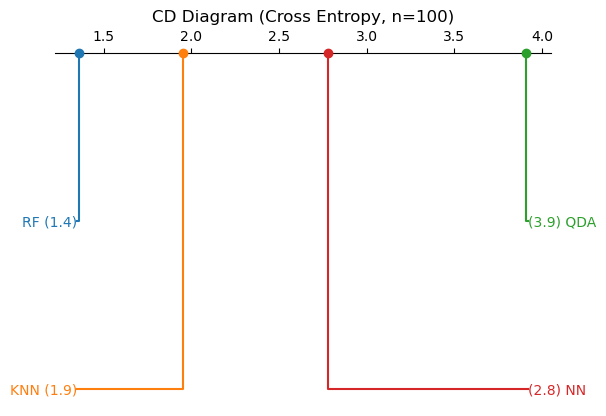

CRITICAL DIFFERENCE DIAGRAM — Cross Entropy — n=1000


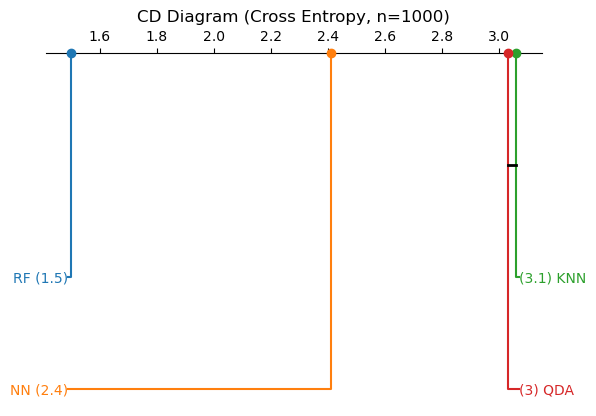

CRITICAL DIFFERENCE DIAGRAM — Cross Entropy — n=5000


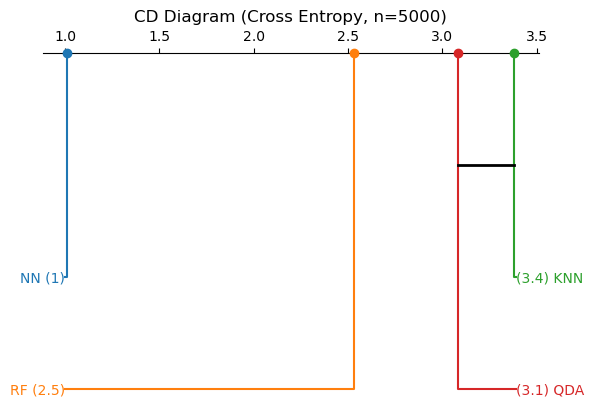

CRITICAL DIFFERENCE DIAGRAM — Cross Entropy — n=10000


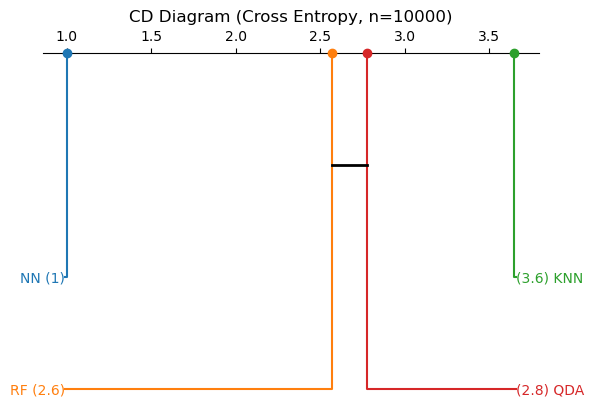

In [13]:
for n in dataset_sizes:
    plot_cd_diagram(
        results[n]['cross_entropy'],
        'Cross Entropy',
        n
    )

#### group models based on thresholded p-values


GROUPED SCORES PLOT — DATASET SIZE n = 100


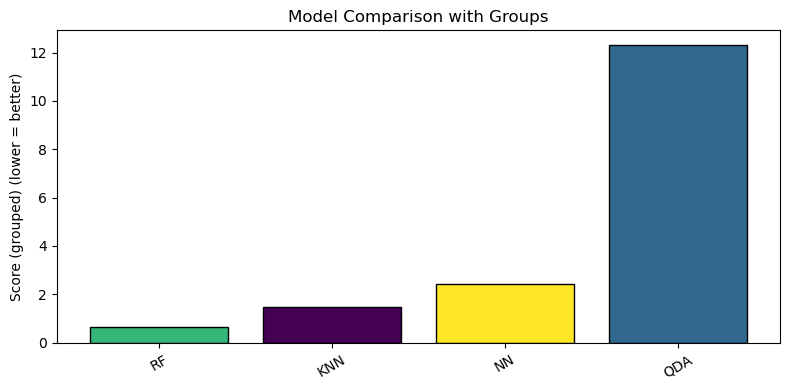


GROUPED SCORES PLOT — DATASET SIZE n = 1000


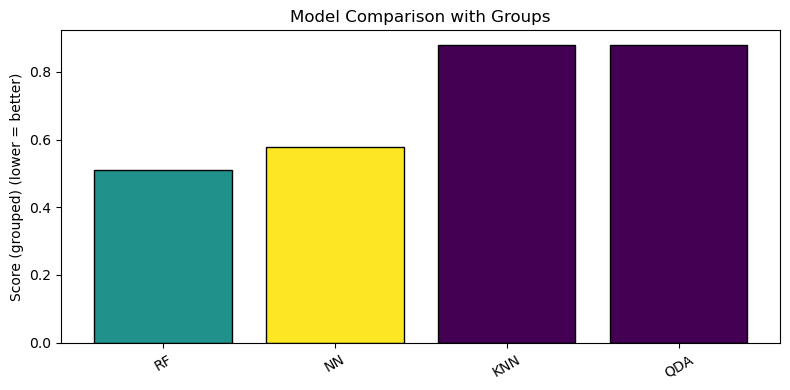


GROUPED SCORES PLOT — DATASET SIZE n = 5000


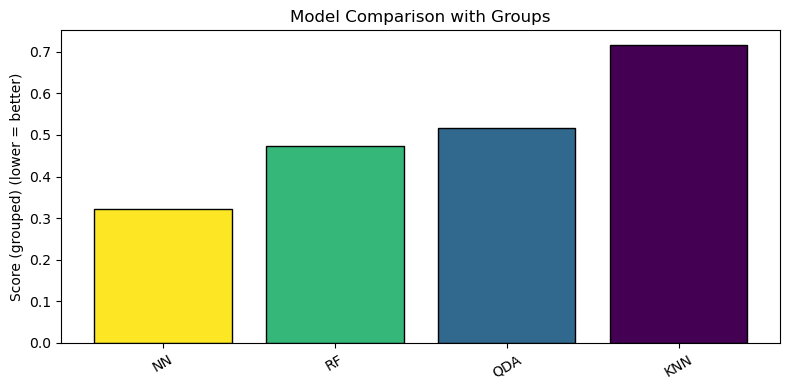


GROUPED SCORES PLOT — DATASET SIZE n = 10000


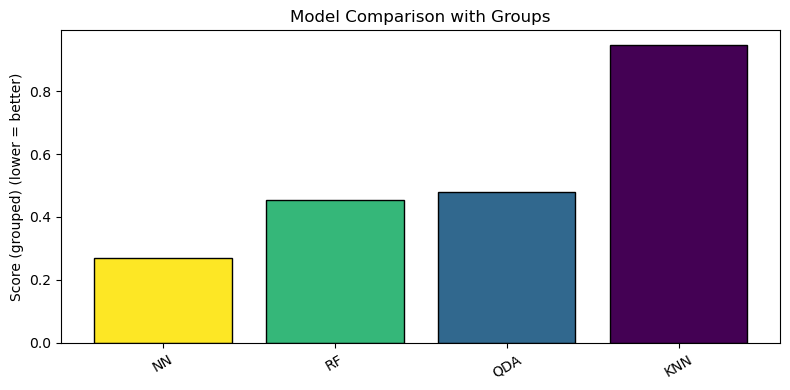

In [14]:
for n in dataset_sizes:

    cross_entropy = results[n]['cross_entropy']

    p_conover = sp.posthoc_conover_friedman(
        cross_entropy,
        p_adjust='holm'
    )

    p_conover_sym = np.array(p_conover, copy=True)

    groups = conover_groups_graph(p_conover_sym, 0.05)

    print("\n" + "="*60)
    print(f"GROUPED SCORES PLOT — DATASET SIZE n = {n}")
    print("="*60)

    plot_grouped_scores(

        groups,
        cross_entropy.mean(axis=0),
        list(cross_entropy.columns),
        higher_is_better=False,
        plot=True
    )



# Part 2


In [15]:
import pandas as pd
from pathlib import Path

# Load the CV results from CSV files

# direction to folder where the results are stored
output_dir = Path("/Users/jonathangao/Documents/Gothenburg University/Courses/MSA220 - Statistical Learning for Big Data/Project 3/resultsModelComparisonsImbalanced") 


# Dataset sizes
dataset_sizes = [5100, 5500, 6000, 7500]

# Store everything in a dictionary
results = {}

for n in dataset_sizes:
    n_str = n

    results[n] = {
        'accuracy': pd.read_csv(output_dir / f'accuracies_n_{n_str}.csv'),
        'balanced_accuracy': pd.read_csv(output_dir / f'balanced_accuracies_n_{n_str}.csv'),
        'cross_entropy': pd.read_csv(output_dir / f'cross_entropies_n_{n_str}.csv'),
        'brier': pd.read_csv(output_dir / f'brier_scores_n_{n_str}.csv')
    }

print(results.keys())


dict_keys([5100, 5500, 6000, 7500])


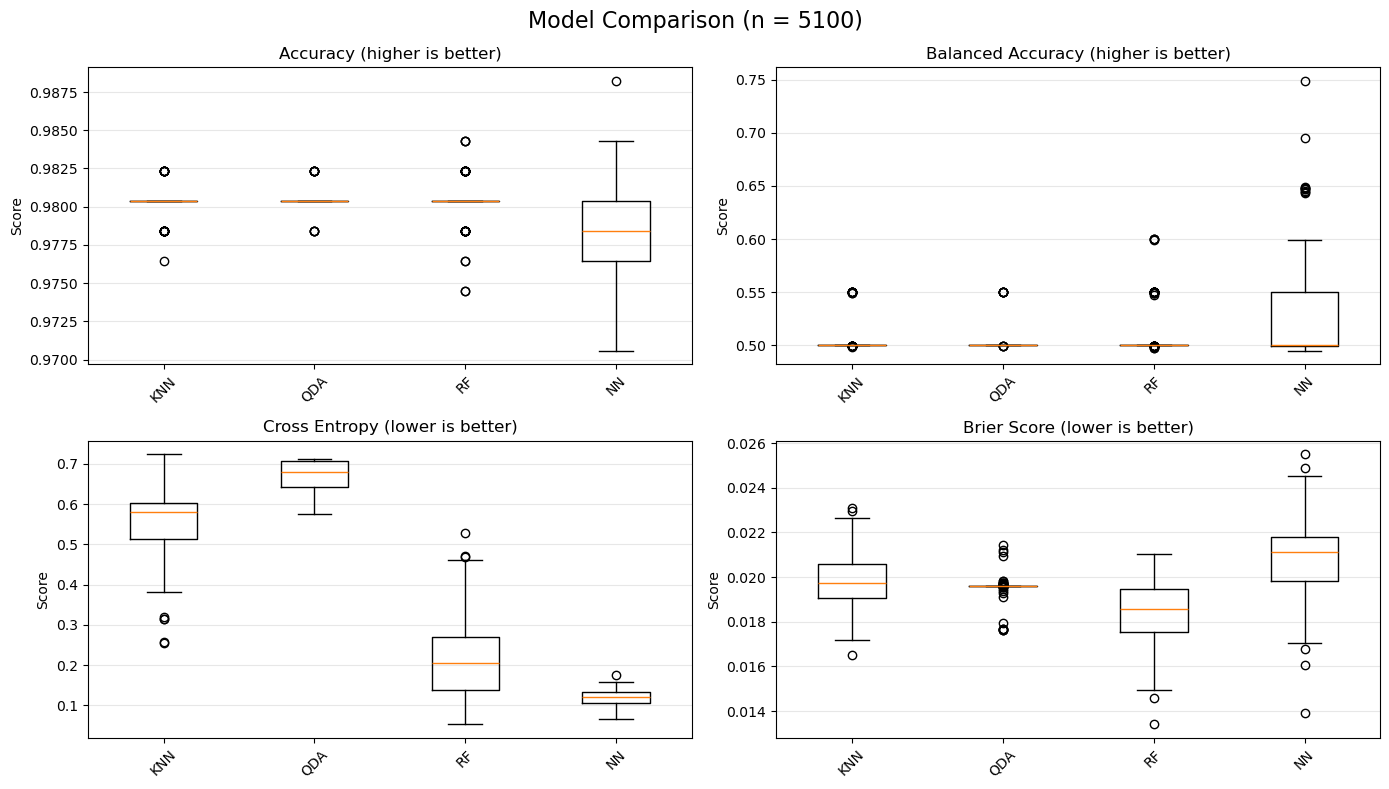

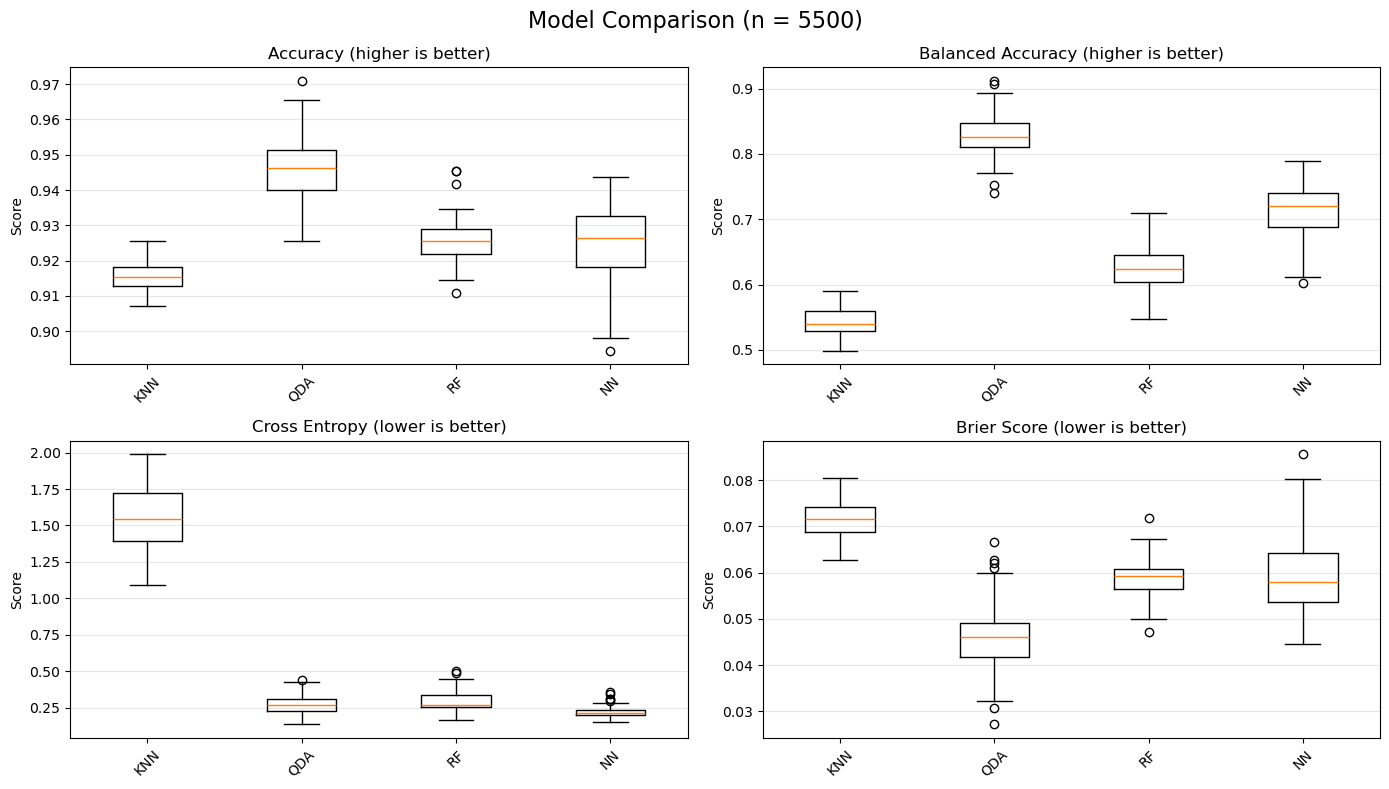

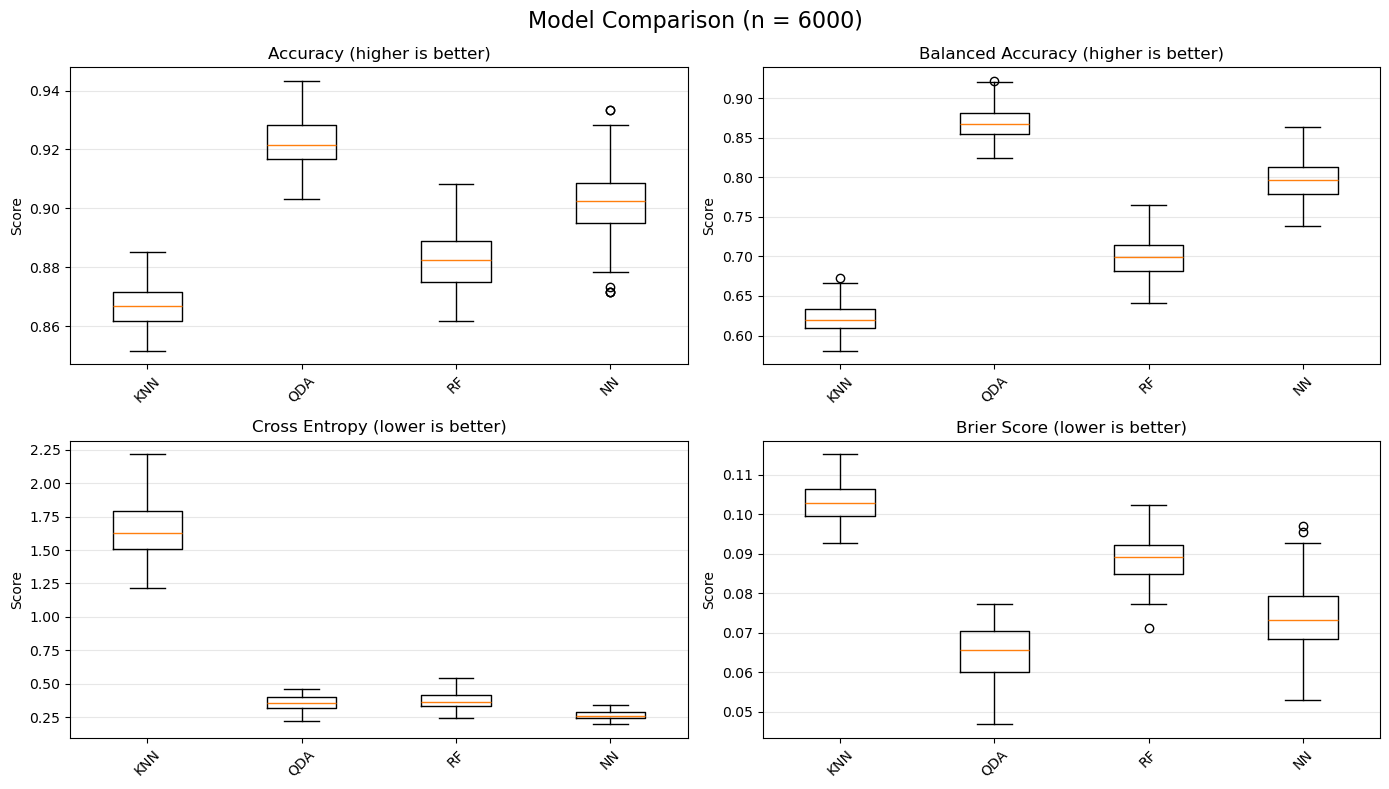

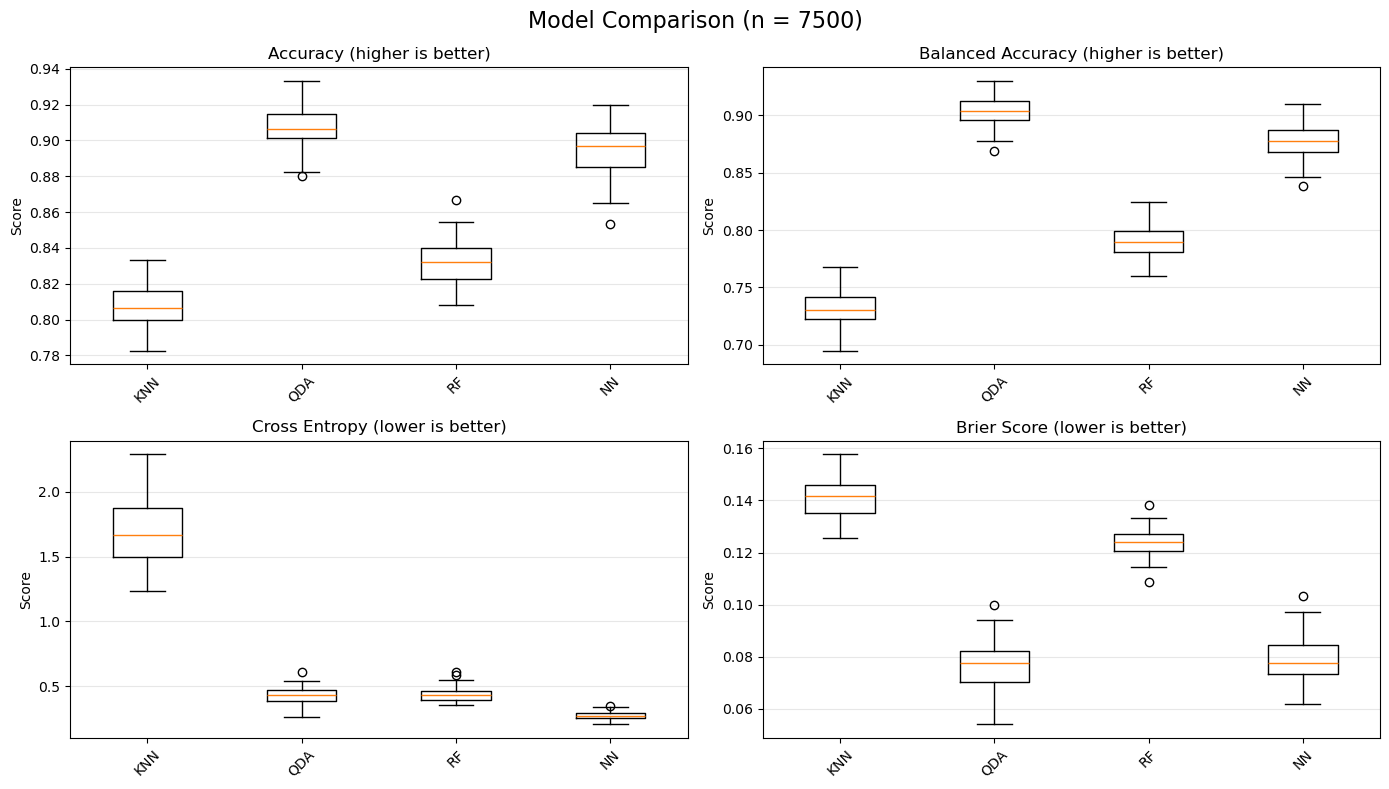

In [16]:
import matplotlib.pyplot as plt
import numpy as np


def plot_metric_boxplots(metrics_dict, n):
    """
    Plot boxplots for all metrics for one dataset size.
    """

    accuracy = metrics_dict['accuracy']
    balanced_accuracy = metrics_dict['balanced_accuracy']
    cross_entropy = metrics_dict['cross_entropy']
    brier = metrics_dict['brier']

    model_names = list(accuracy.columns)
    n_methods = len(model_names)

    fig, axes = plt.subplots(2, 2, figsize=(14, 8))
    axes = axes.flatten()

    metrics = [
        (accuracy, 'Accuracy', True),
        (balanced_accuracy, 'Balanced Accuracy', True),
        (cross_entropy, 'Cross Entropy', False),
        (brier, 'Brier Score', False)
    ]

    for ax, (metric_df, title, higher_is_better) in zip(axes, metrics):
        arr = metric_df.values

        ax.boxplot(
            [arr[:, i] for i in range(n_methods)],
            tick_labels=model_names
        )

        direction = 'higher is better' if higher_is_better else 'lower is better'

        ax.set_title(f'{title} ({direction})')
        ax.set_ylabel('Score')
        ax.grid(axis='y', alpha=0.3)
        ax.tick_params(axis='x', rotation=45)

    fig.suptitle(f'Model Comparison (n = {n})', fontsize=16)
    plt.tight_layout()
    plt.show()

for n in dataset_sizes:
    plot_metric_boxplots(results[n], n)

In [17]:
import numpy as np
from scipy.stats import friedmanchisquare

import numpy as np
from scipy.stats import friedmanchisquare


def run_friedman_test(scores_df, metric_name, n):
    scores_array = np.asarray(scores_df)

    print('=' * 70)
    print(f'FRIEDMAN TEST — {metric_name} — n={n}')
    print('=' * 70)

    stat, pval = friedmanchisquare(*scores_array.T)

    print(f'Test statistic: {stat:.6f}')
    print(f'P-value: {pval:.6e}')
    print(f'Number of methods: {scores_array.shape[1]}')
    print(f'Number of folds: {scores_array.shape[0]}')

    if pval < 0.05:
        print('Result: Significant differences detected.')
    else:
        print('Result: No significant differences detected.')

    print()

    return stat, pval

for n in dataset_sizes:
    run_friedman_test(
        results[n]['balanced_accuracy'],
        'Balanced Accuracy',
        n
    )
  

FRIEDMAN TEST — Balanced Accuracy — n=5100
Test statistic: 1.531825
P-value: 6.749449e-01
Number of methods: 4
Number of folds: 100
Result: No significant differences detected.

FRIEDMAN TEST — Balanced Accuracy — n=5500
Test statistic: 295.392000
P-value: 9.886543e-64
Number of methods: 4
Number of folds: 100
Result: Significant differences detected.

FRIEDMAN TEST — Balanced Accuracy — n=6000
Test statistic: 300.000000
P-value: 9.948758e-65
Number of methods: 4
Number of folds: 100
Result: Significant differences detected.

FRIEDMAN TEST — Balanced Accuracy — n=7500
Test statistic: 295.392000
P-value: 9.886543e-64
Number of methods: 4
Number of folds: 100
Result: Significant differences detected.



In [18]:
from scipy.stats import wilcoxon
from itertools import combinations
from statsmodels.stats.multitest import multipletests


def run_pairwise_tests(scores_df, metric_name, n):
    print('\n' + '=' * 70)
    print(f'POST-HOC PAIRWISE COMPARISONS — {metric_name} — n={n}')
    print('=' * 70)

    n_methods = scores_df.shape[1]
    method_names = list(scores_df.columns)

    pvals_raw = []
    comparisons = []

    for i, j in combinations(range(n_methods), 2):
        stat, pval = wilcoxon(scores_df.iloc[:, i], scores_df.iloc[:, j])

        pvals_raw.append(pval)
        comparisons.append((method_names[i], method_names[j], stat, pval))

    reject, pvals_corrected, _, _ = multipletests(
        pvals_raw,
        method='holm'
    )

    print('\nAdjusted Results:')

    for (m1, m2, stat, raw_p), corrected_p, rej in zip(
        comparisons,
        pvals_corrected,
        reject
    ):
        sig = 'SIGNIFICANT' if rej else 'not significant'

        print(
            f'{m1} vs {m2}: '
            f'raw p={raw_p:.6f}, '
            f'corrected p={corrected_p:.6f} '
            f'-> {sig}'
        )

for n in dataset_sizes:
    run_pairwise_tests(
        results[n]['balanced_accuracy'],
        'Balanced Accuracy',
        n
    )



POST-HOC PAIRWISE COMPARISONS — Balanced Accuracy — n=5100

Adjusted Results:
KNN vs QDA: raw p=0.920163, corrected p=0.920163 -> not significant
KNN vs RF: raw p=0.043014, corrected p=0.103317 -> not significant
KNN vs NN: raw p=0.000542, corrected p=0.003255 -> SIGNIFICANT
QDA vs RF: raw p=0.019828, corrected p=0.079313 -> not significant
QDA vs NN: raw p=0.000729, corrected p=0.003645 -> SIGNIFICANT
RF vs NN: raw p=0.034439, corrected p=0.103317 -> not significant

POST-HOC PAIRWISE COMPARISONS — Balanced Accuracy — n=5500

Adjusted Results:
KNN vs QDA: raw p=0.000000, corrected p=0.000000 -> SIGNIFICANT
KNN vs RF: raw p=0.000000, corrected p=0.000000 -> SIGNIFICANT
KNN vs NN: raw p=0.000000, corrected p=0.000000 -> SIGNIFICANT
QDA vs RF: raw p=0.000000, corrected p=0.000000 -> SIGNIFICANT
QDA vs NN: raw p=0.000000, corrected p=0.000000 -> SIGNIFICANT
RF vs NN: raw p=0.000000, corrected p=0.000000 -> SIGNIFICANT

POST-HOC PAIRWISE COMPARISONS — Balanced Accuracy — n=6000

Adjusted 

In [19]:
import scikit_posthocs as sp


def run_conover_test(scores_df, metric_name, n):
    print('=' * 70)
    print(f'CONOVER-FRIEDMAN TEST — {metric_name} — n={n}')
    print('=' * 70)

    p_conover = sp.posthoc_conover_friedman(
        scores_df,
        p_adjust='holm'
    )

    print(p_conover.round(6))

    return p_conover

for n in dataset_sizes:
    run_conover_test(
        results[n]['balanced_accuracy'],
        'Balanced Accuracy',
        n
    )

CONOVER-FRIEDMAN TEST — Balanced Accuracy — n=5100
     KNN  QDA   RF   NN
KNN  1.0  1.0  1.0  1.0
QDA  1.0  1.0  1.0  1.0
RF   1.0  1.0  1.0  1.0
NN   1.0  1.0  1.0  1.0
CONOVER-FRIEDMAN TEST — Balanced Accuracy — n=5500
     KNN  QDA   RF   NN
KNN  1.0  0.0  0.0  0.0
QDA  0.0  1.0  0.0  0.0
RF   0.0  0.0  1.0  0.0
NN   0.0  0.0  0.0  1.0
CONOVER-FRIEDMAN TEST — Balanced Accuracy — n=6000
     KNN  QDA   RF   NN
KNN  1.0  0.0  0.0  0.0
QDA  0.0  1.0  0.0  0.0
RF   0.0  0.0  1.0  0.0
NN   0.0  0.0  0.0  1.0
CONOVER-FRIEDMAN TEST — Balanced Accuracy — n=7500
     KNN  QDA   RF   NN
KNN  1.0  0.0  0.0  0.0
QDA  0.0  1.0  0.0  0.0
RF   0.0  0.0  1.0  0.0
NN   0.0  0.0  0.0  1.0


/opt/miniconda3/envs/DIT408env/lib/python3.10/site-packages/scikit_posthocs/_posthocs.py:736: RuntimeWarning: divide by zero encountered in scalar divide
  tval = dif / np.sqrt(A) / np.sqrt(B)


In [20]:
def run_nemenyi_test(scores_df, metric_name, n):
    print('=' * 70)
    print(f'NEMENYI TEST — {metric_name} — n={n}')
    print('=' * 70)

    p_nemenyi = sp.posthoc_nemenyi_friedman(scores_df)

    print(p_nemenyi.round(6))

    return p_nemenyi

for n in dataset_sizes:
    run_nemenyi_test(
        results[n]['balanced_accuracy'],
        'Balanced Accuracy',
        n
    )

NEMENYI TEST — Balanced Accuracy — n=5100
          KNN       QDA        RF        NN
KNN  1.000000  0.954234  0.773009  0.844289
QDA  0.954234  1.000000  0.971866  0.990508
RF   0.773009  0.971866  1.000000  0.999084
NN   0.844289  0.990508  0.999084  1.000000
NEMENYI TEST — Balanced Accuracy — n=5500
     KNN  QDA        RF        NN
KNN  1.0  0.0  0.000000  0.000000
QDA  0.0  1.0  0.000000  0.000000
RF   0.0  0.0  1.000000  0.000003
NN   0.0  0.0  0.000003  1.000000
NEMENYI TEST — Balanced Accuracy — n=6000
     KNN  QDA   RF   NN
KNN  1.0  0.0  0.0  0.0
QDA  0.0  1.0  0.0  0.0
RF   0.0  0.0  1.0  0.0
NN   0.0  0.0  0.0  1.0
NEMENYI TEST — Balanced Accuracy — n=7500
     KNN       QDA   RF        NN
KNN  1.0  0.000000  0.0  0.000000
QDA  0.0  1.000000  0.0  0.000003
RF   0.0  0.000000  1.0  0.000000
NN   0.0  0.000003  0.0  1.000000


CRITICAL DIFFERENCE DIAGRAM — Balanced Accuracy — n=5100


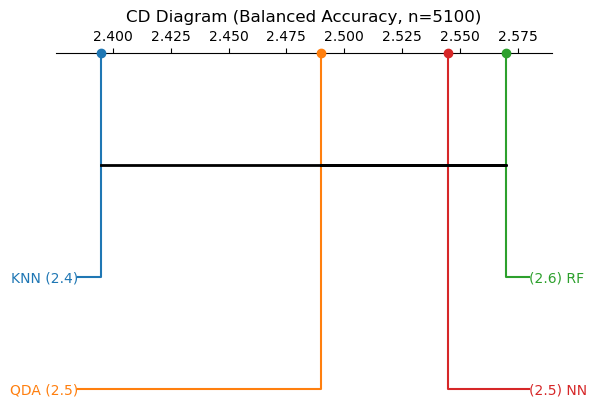

CRITICAL DIFFERENCE DIAGRAM — Balanced Accuracy — n=5500


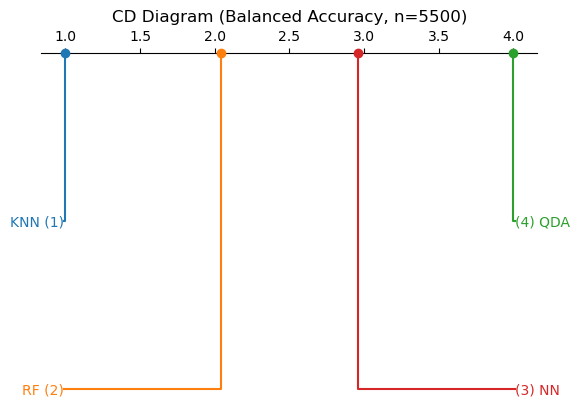

CRITICAL DIFFERENCE DIAGRAM — Balanced Accuracy — n=6000


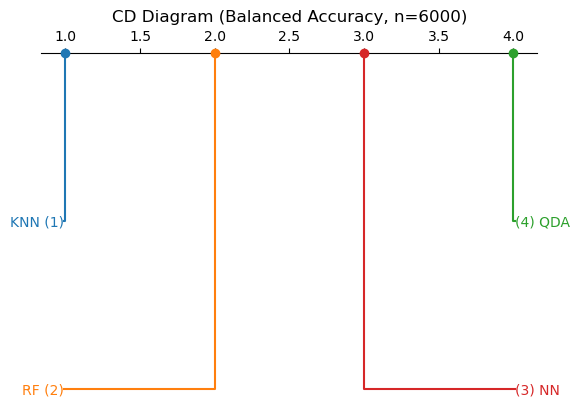

CRITICAL DIFFERENCE DIAGRAM — Balanced Accuracy — n=7500


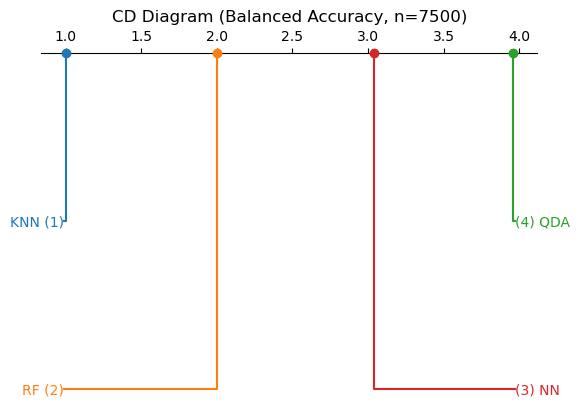

In [21]:
from scipy.stats import rankdata
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import scikit_posthocs as sp


def plot_cd_diagram(scores_df, metric_name, n):
    ranks = np.array([
        rankdata(row)
        for row in scores_df.values
    ])

    mean_ranks = ranks.mean(axis=0)

    mean_ranks_series = pd.Series(
        mean_ranks,
        index=scores_df.columns
    )

    print('=' * 70)
    print(f'CRITICAL DIFFERENCE DIAGRAM — {metric_name} — n={n}')
    print('=' * 70)

    p_nemenyi = sp.posthoc_nemenyi_friedman(scores_df) # Uses p-values from Nemenyi test for CD diagram!


    # Create symmetric p-value DataFrame for CD diagram
    p_nemenyi_for_cd = pd.DataFrame(p_nemenyi, 
                                    index=scores_df.columns, 
                                    columns=scores_df.columns)

    sp.critical_difference_diagram(
        mean_ranks_series,
        p_nemenyi_for_cd
    )

    plt.title(f'CD Diagram ({metric_name}, n={n})')
    plt.show()


# Plot CD diagrams for each dataset size for balanced accuracy
for n in dataset_sizes:
    plot_cd_diagram(
        results[n]['balanced_accuracy'],
        'Balanced Accuracy',
        n
    )



GROUPED SCORES PLOT — DATASET SIZE n = 5100


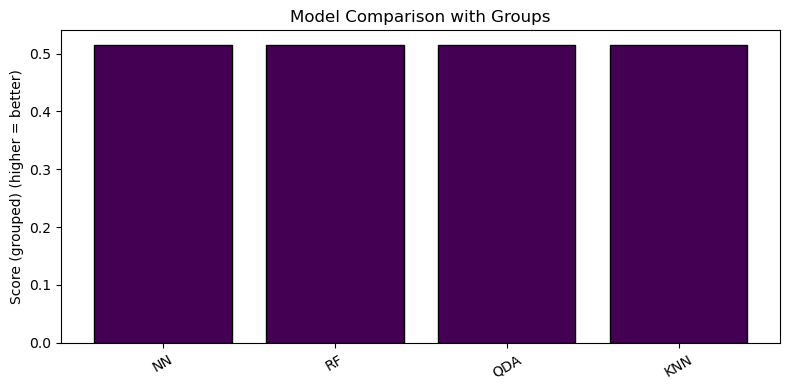


GROUPED SCORES PLOT — DATASET SIZE n = 5500


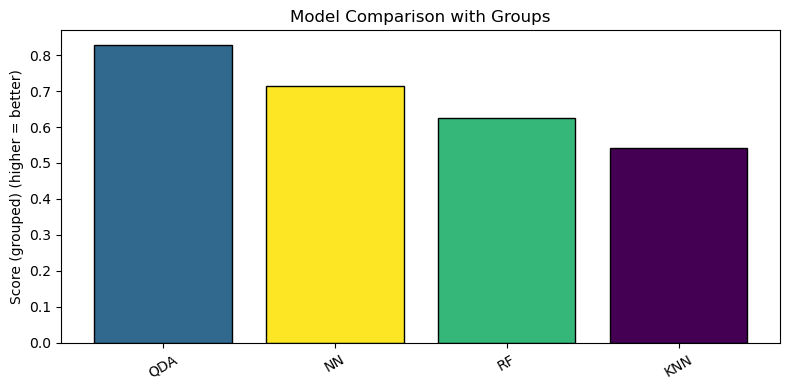


GROUPED SCORES PLOT — DATASET SIZE n = 6000


/opt/miniconda3/envs/DIT408env/lib/python3.10/site-packages/scikit_posthocs/_posthocs.py:736: RuntimeWarning: divide by zero encountered in scalar divide
  tval = dif / np.sqrt(A) / np.sqrt(B)


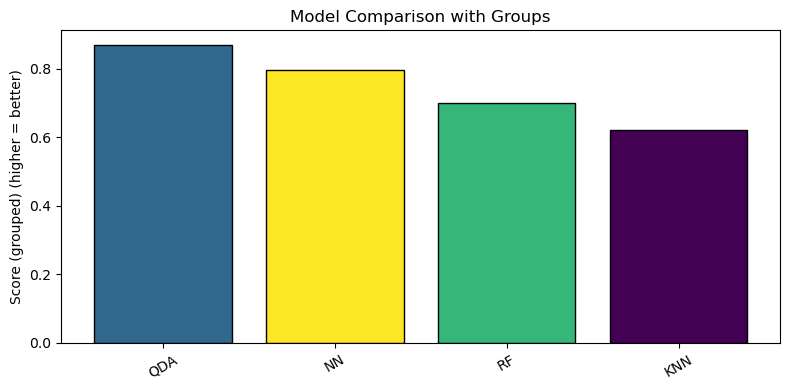


GROUPED SCORES PLOT — DATASET SIZE n = 7500


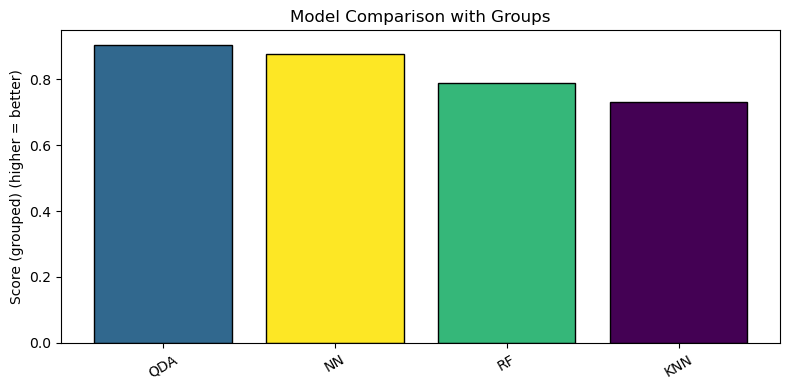

In [22]:
import networkx as nx
import matplotlib.pyplot as plt
import numpy as np


def conover_groups_graph(p_matrix, alpha=0.05):
    M = p_matrix.shape[0]

    G = nx.Graph()
    G.add_nodes_from(range(M))

    for i in range(M):
        for j in range(i+1, M):
            if p_matrix[i, j] >= alpha:
                G.add_edge(i, j)

    return list(nx.connected_components(G))

def rank_groups(groups, score, higher_is_better=True):
    score = np.asarray(score) 

    ranked = []

    for g in groups:
        g_list = list(g)
        g_score = np.mean([score[i] for i in g_list])

        ranked.append((g_list, g_score))

    ranked.sort(key=lambda x: x[1], reverse=higher_is_better)

    return ranked


def groups_to_rank_vector(groups, M):
    rank_vec = np.zeros(M)

    for rank, group in enumerate(groups, start=1):
        for i in group:
            rank_vec[i] = rank

    return rank_vec

def grouped_scores(groups, score):
    """
    Compute grouped score vector (same value within groups).

    Returns scores in ORIGINAL order.
    """
    score = np.asarray(score)
    M = len(score)

    group_scores = np.zeros(M)

    for g in groups:
        g = list(g)
        s = np.mean(score[g])
        for i in g:
            group_scores[i] = s

    return group_scores

def plot_grouped_scores(
    groups,
    score,
    names,
    higher_is_better=True,
    plot=True
):
    import numpy as np
    import matplotlib.pyplot as plt

    score = np.asarray(score)
    names = list(names)
    M = len(score)

    group_scores = np.zeros(M)

    for g in groups:
        g = list(g)
        s = np.mean(score[g])
        for i in g:
            group_scores[i] = s

    if plot is False:
        return group_scores


    group_ids = np.zeros(M)

    for gid, g in enumerate(groups):
        for i in g:
            group_ids[i] = gid

    colors = group_ids / group_ids.max() if group_ids.max() > 0 else group_ids

    order = np.argsort(group_scores)

    if higher_is_better:
        order = order[::-1]

    grouped_sorted = group_scores[order]
    names_sorted = np.array(names)[order]
    colors_sorted = colors[order]

    plt.figure(figsize=(8, 4))

    plt.bar(
        names_sorted,
        grouped_sorted,
        color=plt.cm.viridis(colors_sorted),
        edgecolor='black'
    )

    plt.xticks(rotation=30)

    ylabel = "Score (grouped)"
    ylabel += " (higher = better)" if higher_is_better else " (lower = better)"

    plt.ylabel(ylabel)
    plt.title("Model Comparison with Groups")

    plt.tight_layout()
    plt.show()

    return group_scores

for n in dataset_sizes:

    balanced_accuracy = results[n]['balanced_accuracy']

    p_conover = sp.posthoc_conover_friedman(
        balanced_accuracy,
        p_adjust='holm'
    )

    p_conover_sym = np.array(p_conover, copy=True)

    groups = conover_groups_graph(p_conover_sym, 0.05)

    print("\n" + "="*60)
    print(f"GROUPED SCORES PLOT — DATASET SIZE n = {n}")
    print("="*60)

    plot_grouped_scores(


        groups,
        balanced_accuracy.mean(axis=0),
        list(balanced_accuracy.columns),
        higher_is_better=True,
        plot=True
    )



FRIEDMAN TEST — Cross Entropy — n=5100
Test statistic: 271.572000
P-value: 1.410466e-58
Number of methods: 4
Number of folds: 100
Result: Significant differences detected.


POST-HOC PAIRWISE COMPARISONS — Cross Entropy — n=5100

Adjusted Results:
KNN vs QDA: raw p=0.000000, corrected p=0.000000 -> SIGNIFICANT
KNN vs RF: raw p=0.000000, corrected p=0.000000 -> SIGNIFICANT
KNN vs NN: raw p=0.000000, corrected p=0.000000 -> SIGNIFICANT
QDA vs RF: raw p=0.000000, corrected p=0.000000 -> SIGNIFICANT
QDA vs NN: raw p=0.000000, corrected p=0.000000 -> SIGNIFICANT
RF vs NN: raw p=0.000000, corrected p=0.000000 -> SIGNIFICANT
CONOVER-FRIEDMAN TEST — Cross Entropy — n=5100
     KNN  QDA   RF   NN
KNN  1.0  0.0  0.0  0.0
QDA  0.0  1.0  0.0  0.0
RF   0.0  0.0  1.0  0.0
NN   0.0  0.0  0.0  1.0
NEMENYI TEST — Cross Entropy — n=5100
          KNN       QDA        RF        NN
KNN  1.000000  0.000054  0.000000  0.000000
QDA  0.000054  1.000000  0.000000  0.000000
RF   0.000000  0.000000  1.000000  0.

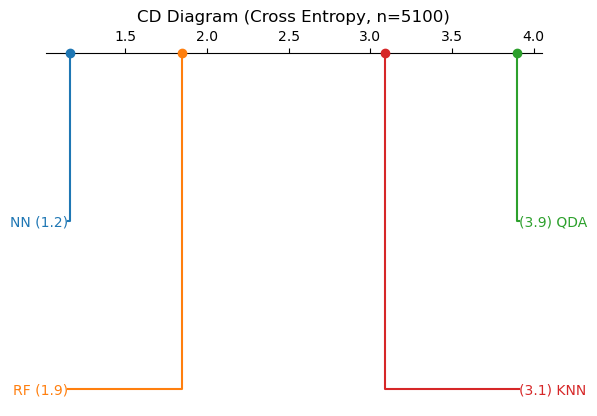


GROUPED SCORES PLOT — DATASET SIZE n = 5100


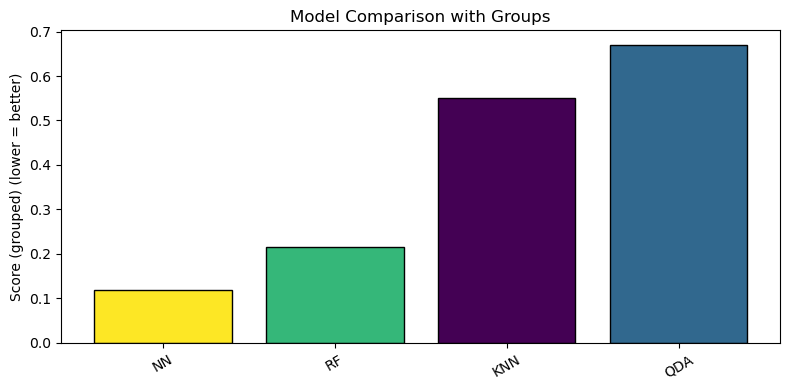

FRIEDMAN TEST — Cross Entropy — n=5500
Test statistic: 214.644000
P-value: 2.887064e-46
Number of methods: 4
Number of folds: 100
Result: Significant differences detected.


POST-HOC PAIRWISE COMPARISONS — Cross Entropy — n=5500

Adjusted Results:
KNN vs QDA: raw p=0.000000, corrected p=0.000000 -> SIGNIFICANT
KNN vs RF: raw p=0.000000, corrected p=0.000000 -> SIGNIFICANT
KNN vs NN: raw p=0.000000, corrected p=0.000000 -> SIGNIFICANT
QDA vs RF: raw p=0.030829, corrected p=0.030829 -> SIGNIFICANT
QDA vs NN: raw p=0.000000, corrected p=0.000000 -> SIGNIFICANT
RF vs NN: raw p=0.000000, corrected p=0.000000 -> SIGNIFICANT
CONOVER-FRIEDMAN TEST — Cross Entropy — n=5500
     KNN      QDA       RF   NN
KNN  1.0  0.00000  0.00000  0.0
QDA  0.0  1.00000  0.68307  0.0
RF   0.0  0.68307  1.00000  0.0
NN   0.0  0.00000  0.00000  1.0
NEMENYI TEST — Cross Entropy — n=5500
     KNN       QDA        RF        NN
KNN  1.0  0.000000  0.000000  0.000000
QDA  0.0  1.000000  0.996290  0.000004
RF   0.0  0.

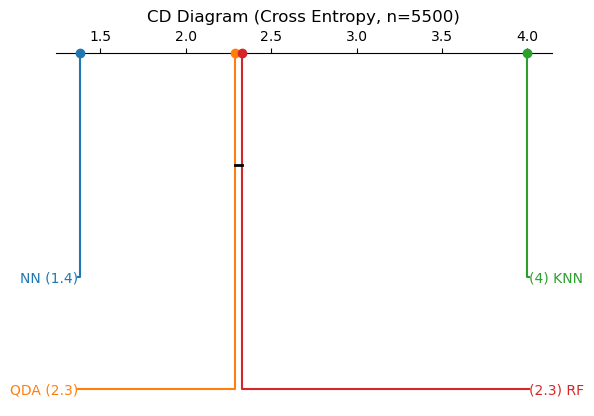


GROUPED SCORES PLOT — DATASET SIZE n = 5500


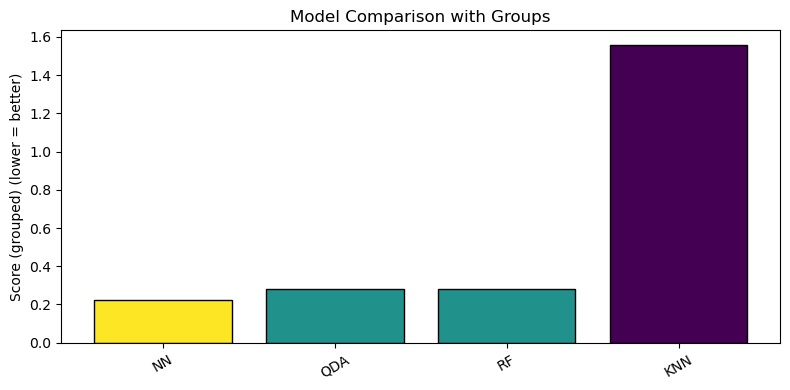

FRIEDMAN TEST — Cross Entropy — n=6000
Test statistic: 256.608000
P-value: 2.435222e-55
Number of methods: 4
Number of folds: 100
Result: Significant differences detected.


POST-HOC PAIRWISE COMPARISONS — Cross Entropy — n=6000

Adjusted Results:
KNN vs QDA: raw p=0.000000, corrected p=0.000000 -> SIGNIFICANT
KNN vs RF: raw p=0.000000, corrected p=0.000000 -> SIGNIFICANT
KNN vs NN: raw p=0.000000, corrected p=0.000000 -> SIGNIFICANT
QDA vs RF: raw p=0.090058, corrected p=0.090058 -> not significant
QDA vs NN: raw p=0.000000, corrected p=0.000000 -> SIGNIFICANT
RF vs NN: raw p=0.000000, corrected p=0.000000 -> SIGNIFICANT
CONOVER-FRIEDMAN TEST — Cross Entropy — n=6000
     KNN       QDA        RF   NN
KNN  1.0  0.000000  0.000000  0.0
QDA  0.0  1.000000  0.086556  0.0
RF   0.0  0.086556  1.000000  0.0
NN   0.0  0.000000  0.000000  1.0
NEMENYI TEST — Cross Entropy — n=6000
     KNN       QDA        RF   NN
KNN  1.0  0.000000  0.000000  0.0
QDA  0.0  1.000000  0.913024  0.0
RF   0.0  0.9

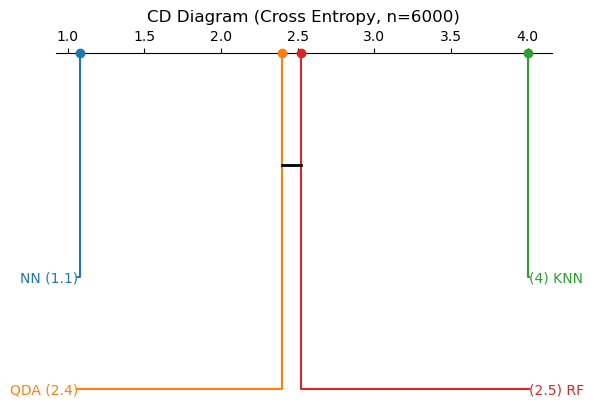


GROUPED SCORES PLOT — DATASET SIZE n = 6000


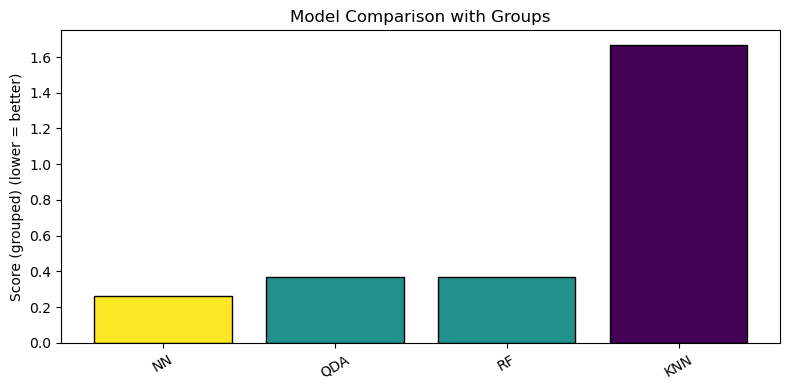

FRIEDMAN TEST — Cross Entropy — n=7500
Test statistic: 266.868000
P-value: 1.469118e-57
Number of methods: 4
Number of folds: 100
Result: Significant differences detected.


POST-HOC PAIRWISE COMPARISONS — Cross Entropy — n=7500

Adjusted Results:
KNN vs QDA: raw p=0.000000, corrected p=0.000000 -> SIGNIFICANT
KNN vs RF: raw p=0.000000, corrected p=0.000000 -> SIGNIFICANT
KNN vs NN: raw p=0.000000, corrected p=0.000000 -> SIGNIFICANT
QDA vs RF: raw p=0.247977, corrected p=0.247977 -> not significant
QDA vs NN: raw p=0.000000, corrected p=0.000000 -> SIGNIFICANT
RF vs NN: raw p=0.000000, corrected p=0.000000 -> SIGNIFICANT
CONOVER-FRIEDMAN TEST — Cross Entropy — n=7500
     KNN       QDA        RF   NN
KNN  1.0  0.000000  0.000000  0.0
QDA  0.0  1.000000  0.050013  0.0
RF   0.0  0.050013  1.000000  0.0
NN   0.0  0.000000  0.000000  1.0
NEMENYI TEST — Cross Entropy — n=7500
     KNN       QDA        RF   NN
KNN  1.0  0.000000  0.000000  0.0
QDA  0.0  1.000000  0.913024  0.0
RF   0.0  0.9

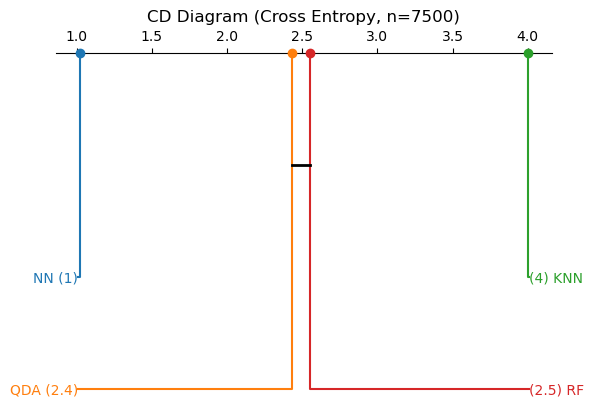


GROUPED SCORES PLOT — DATASET SIZE n = 7500


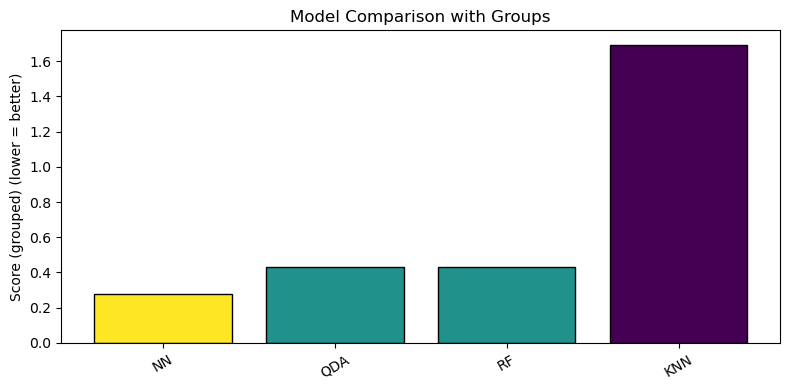

In [23]:
for n in dataset_sizes:
    run_friedman_test(
        results[n]['cross_entropy'],
        'Cross Entropy',
        n
    )  

    run_pairwise_tests(
        results[n]['cross_entropy'],
        'Cross Entropy',
        n
    )
    
    run_conover_test(
        results[n]['cross_entropy'],
        'Cross Entropy',
        n
    )

    run_nemenyi_test(
    results[n]['cross_entropy'],
    'Cross Entropy',
    n
    )

    plot_cd_diagram(
        results[n]['cross_entropy'],
        'Cross Entropy',
        n
    )

    cross_entropy = results[n]['cross_entropy']

    p_conover = sp.posthoc_conover_friedman(
        cross_entropy,
        p_adjust='holm'
    )

    p_conover_sym = np.array(p_conover, copy=True)

    groups = conover_groups_graph(p_conover_sym, 0.05)

    print("\n" + "="*60)
    print(f"GROUPED SCORES PLOT — DATASET SIZE n = {n}")
    print("="*60)

    plot_grouped_scores(


        groups,
        cross_entropy.mean(axis=0),
        list(cross_entropy.columns),
        higher_is_better=False,
        plot=True
    )
